# 03 - Biomarker identification: the top 10 ncRNAs

**Objective 3** (Aims 3.1-3.3). Data: GSE120584 serum miRNA, **training split only**, AD vs NC.

**Approach (from the analysis plan):**
1. Four ranking methods, each including age, sex, APOE4 and sample quality as covariates, so ncRNAs are ranked by
   what they add **beyond** clinical factors: **LASSO**, **RFE**, **Random Forest importance**, **SHAP** (XGBoost).
2. **Stability:** repeat on 25 resamples (5-fold x 5 repeats). For each method, an ncRNA's score is how often it lands
   in that method's top 20 (selection frequency).
3. **Consensus top 10:** ncRNAs stable (frequency >= 50%) in at least 2 of the 4 methods, ordered by mean frequency.
4. **Honest panel performance:** the whole selection procedure is repeated inside each outer CV fold, then a
   10-ncRNA + clinical model is tested on the held-out fold (no leakage).
5. **Biological interpretation:** direction of change, confounder checks, known AD ncRNAs, and availability in the
   external validation datasets.

In [1]:
import os, sys, warnings
os.environ.setdefault("OMP_NUM_THREADS", "1")
sys.path.append("../src")
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from utils import load_dataset, ROOT, FIGURES, PROCESSED, SEED
from modeling import detection_rate, make_features, CLINICAL, QUALITY, bootstrap_auc_diff
from biomarkers import METHODS, stability_ranking, consensus

TAB = ROOT / "results" / "tables"
MOD = ROOT / "results" / "models"
FIG = FIGURES / "03_biomarkers"; FIG.mkdir(parents=True, exist_ok=True)
RERUN = False
sns.set_theme(style="whitegrid")
def savefig(n): plt.savefig(FIG / f"{n}.png", dpi=150, bbox_inches="tight")

In [2]:
X, clin = load_dataset("GSE120584_serum", split="train", diagnoses=["AD", "NC"])
clin["detect_rate"] = detection_rate(X)
ncrna = pd.read_csv(TAB / "01_eda_filtered_mirnas.csv")["miRNA"].tolist()
F = make_features(X[ncrna], clin)
y = (clin["diagnosis"] == "AD").astype(int)
COV = CLINICAL + QUALITY
print(f"{len(y)} samples (AD {y.sum()}, NC {(1-y).sum()}), {len(ncrna)} ncRNAs + covariates {COV}")

1046 samples (AD 816, NC 230), 817 ncRNAs + covariates ['age', 'female', 'apoe4', 'detect_rate']


## 1. Stability ranking on the full training split (25 resamples x 4 methods)

In [3]:
cache = MOD / "03_stability_full.joblib"
if cache.exists() and not RERUN:
    freq, mean_rank = joblib.load(cache)
else:
    freq, mean_rank = stability_ranking(F, y, ncrna, n_splits=5, n_repeats=5, top_n=20)
    joblib.dump((freq, mean_rank), cache)

table, top10 = consensus(freq, mean_rank, n_top=10, min_freq=0.5, min_methods=2)
table.to_csv(TAB / "03_ncrna_ranking_all.csv")
print(f"ncRNAs stable in >= 2 methods: {table.qualifies.sum()}")
table.head(25).round(2)

ncRNAs stable in >= 2 methods: 20


,freq_LASSO,freq_RFE,freq_RF,freq_SHAP,mean_freq,n_methods_stable,mean_rank,qualifies,consensus_rank
hsa-miR-128-1-5p,1.00,0.92,0.84,0.40,0.79,3,15.22,True,1
hsa-miR-3917,0.92,0.96,0.40,0.80,0.77,3,17.21,True,2
hsa-miR-4667-5p,0.08,0.76,1.00,1.00,0.71,3,24.48,True,3
hsa-miR-1471,0.40,0.68,1.00,0.60,0.67,3,26.39,True,4
hsa-miR-6861-5p,0.92,0.92,0.00,0.80,0.66,3,33.05,True,5
hsa-miR-3122,0.52,0.60,0.76,0.68,0.64,4,46.42,True,6
hsa-miR-6743-5p,0.96,0.96,0.00,0.60,0.63,3,29.76,True,7
hsa-miR-3689d,0.80,0.88,0.12,0.48,0.57,2,31.72,True,8
hsa-miR-6840-3p,0.16,0.72,1.00,0.40,0.57,2,36.15,True,9
hsa-miR-6784-5p,0.16,0.12,1.00,0.96,0.56,2,126.95,True,10


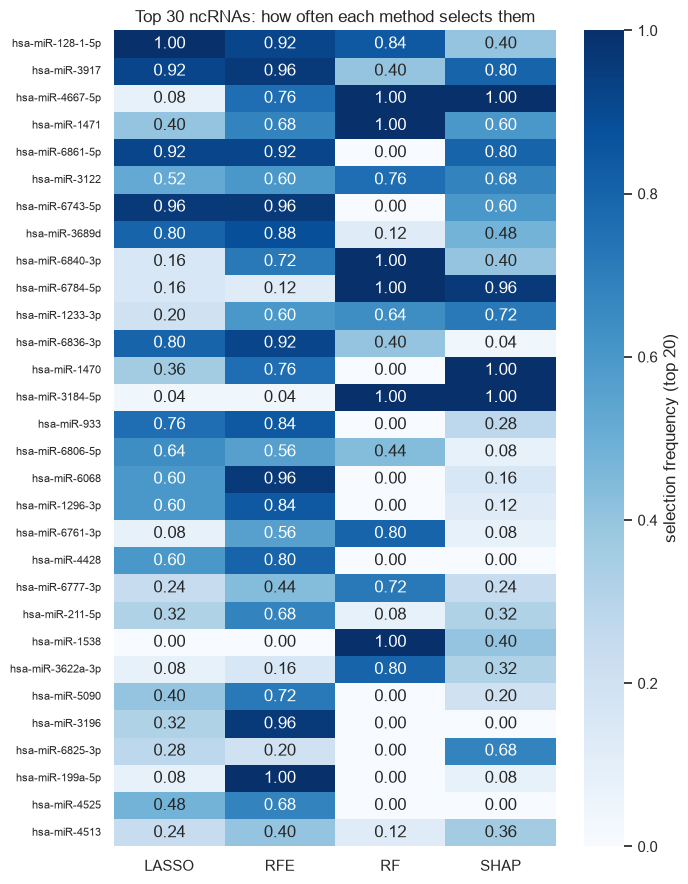

Agreement between methods (Spearman correlation of mean ranks, all ncRNAs):


,LASSO,RFE,RF,SHAP
LASSO,1.00,0.55,0.26,0.45
RFE,0.55,1.00,0.13,0.27
RF,0.26,0.13,1.00,0.58
SHAP,0.45,0.27,0.58,1.00


In [4]:
show = table.head(30)
plt.figure(figsize=(7, 9))
sns.heatmap(show[[f"freq_{m}" for m in METHODS]].rename(columns=lambda c: c[5:]), annot=True, fmt=".2f",
            cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "selection frequency (top 20)"})
plt.yticks(fontsize=8); plt.title("Top 30 ncRNAs: how often each method selects them")
plt.tight_layout(); savefig("selection_frequency_heatmap"); plt.show()

print("Agreement between methods (Spearman correlation of mean ranks, all ncRNAs):")
mean_rank.corr(method="spearman").round(2)

## 2. The consensus top 10 ncRNAs

In [5]:
eda = pd.read_csv(TAB / "01_eda_AD_vs_NC_univariate.csv", index_col=0)
det_all = X.sub(X.min(axis=1), axis=0).gt(1e-6).mean(axis=0)

top = table.loc[top10, [f"freq_{m}" for m in METHODS] + ["mean_freq", "n_methods_stable"]].copy()
top["direction_in_AD"] = np.where(eda.loc[top10, "beta_adj"] > 0, "up", "down")
top["log2FC"] = eda.loc[top10, "log2FC"]
top["single_AUC"] = eda.loc[top10, "auc"].map(lambda a: max(a, 1 - a))
top["FDR_adjusted"] = eda.loc[top10, "fdr_adj"]
top["FDR_adj_quality"] = eda.loc[top10, "fdr_adj_q"]
nc_mask = clin.diagnosis == "NC"
top["age_rho_NC"] = [stats.spearmanr(clin.loc[nc_mask, "age"], X.loc[nc_mask, m])[0] for m in top10]
top["detect_rate"] = det_all[top10]
top["rho_detect_rate"] = [stats.spearmanr(X[m], clin.detect_rate)[0] for m in top10]
top.insert(0, "rank", range(1, len(top) + 1))
top.round(3)

,rank,freq_LASSO,freq_RFE,freq_RF,freq_SHAP,mean_freq,n_methods_stable,direction_in_AD,log2FC,single_AUC,FDR_adjusted,FDR_adj_quality,age_rho_NC,detect_rate,rho_detect_rate
hsa-miR-128-1-5p,1,1.00,0.92,0.84,0.40,0.79,3,down,-0.220,0.666,0.000,0.000,-0.185,1.000,0.105
hsa-miR-3917,2,0.92,0.96,0.40,0.80,0.77,3,down,-0.149,0.587,0.000,0.000,0.011,0.997,-0.106
hsa-miR-4667-5p,3,0.08,0.76,1.00,1.00,0.71,3,down,-0.188,0.641,0.002,0.000,-0.222,1.000,0.215
hsa-miR-1471,4,0.40,0.68,1.00,0.60,0.67,3,up,0.346,0.666,0.000,0.000,0.076,0.951,0.264
hsa-miR-6861-5p,5,0.92,0.92,0.00,0.80,0.66,3,down,-0.100,0.581,0.000,0.000,0.060,1.000,-0.119
hsa-miR-3122,6,0.52,0.60,0.76,0.68,0.64,4,up,0.205,0.614,0.020,0.080,0.081,0.966,0.088
hsa-miR-6743-5p,7,0.96,0.96,0.00,0.60,0.63,3,down,-0.088,0.554,0.000,0.001,0.222,1.000,-0.040
hsa-miR-3689d,8,0.80,0.88,0.12,0.48,0.57,2,down,-0.135,0.547,0.000,0.008,0.074,0.945,-0.214
hsa-miR-6840-3p,9,0.16,0.72,1.00,0.40,0.57,2,up,0.340,0.688,0.000,0.000,0.377,1.000,0.001
hsa-miR-6784-5p,10,0.16,0.12,1.00,0.96,0.56,2,down,-0.143,0.638,0.000,0.000,0.052,1.000,-0.062


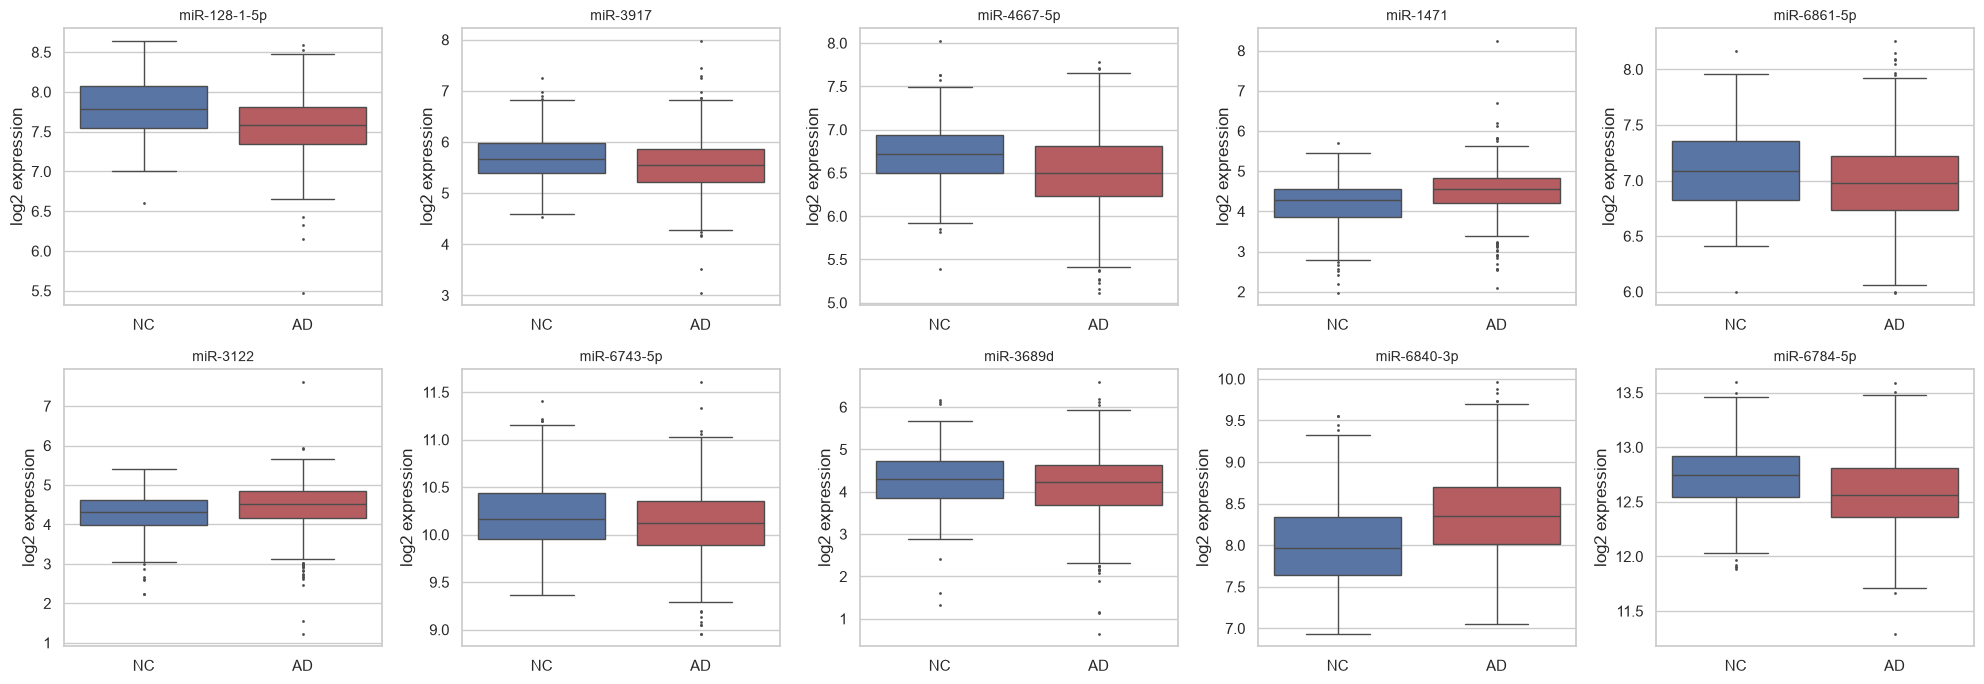

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, m in zip(axes.flat, top10):
    sns.boxplot(data=clin.assign(v=X[m]), x="diagnosis", y="v", order=["NC", "AD"], hue="diagnosis",
                palette={"NC": "#4C72B0", "AD": "#C44E52"}, legend=False, ax=ax, fliersize=1)
    ax.set_title(m.replace("hsa-", ""), fontsize=10); ax.set_xlabel(""); ax.set_ylabel("log2 expression")
plt.tight_layout(); savefig("top10_boxplots"); plt.show()

## 3. SHAP explanation (Aim 3.2)

XGBoost fit on the full training split with the top 10 ncRNAs + covariates. Each dot is one person; colour shows
whether the feature value is high (red) or low (blue); position shows whether it pushes the prediction toward AD
(right) or NC (left).

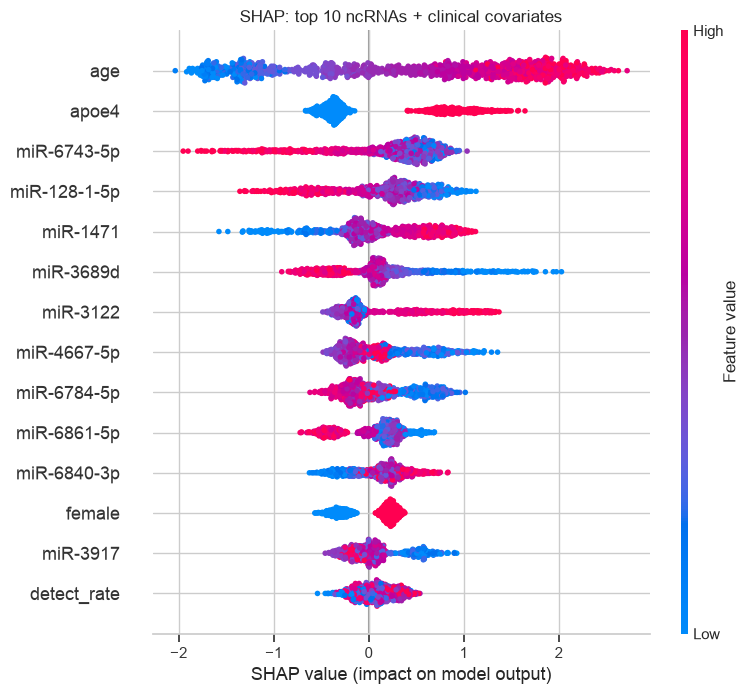

Mean |SHAP| (share of total):


age             0.214
apoe4           0.103
miR-6743-5p     0.091
miR-128-1-5p    0.079
miR-1471        0.072
miR-3689d       0.065
miR-3122        0.062
miR-4667-5p     0.055
miR-6784-5p     0.054
miR-6861-5p     0.047
miR-6840-3p     0.045
female          0.045
miR-3917        0.037
detect_rate     0.031
dtype: float32

In [7]:
cols = top10 + COV
sc = StandardScaler().fit(F[cols])
Z = pd.DataFrame(sc.transform(F[cols]), index=F.index, columns=[c.replace("hsa-", "") for c in cols])
spw = (y == 0).sum() / (y == 1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=spw, eval_metric="logloss", random_state=SEED, n_jobs=1, verbosity=0).fit(Z, y)
sv = shap.TreeExplainer(xgb)(Z)
shap.plots.beeswarm(sv, max_display=14, show=False)
plt.title("SHAP: top 10 ncRNAs + clinical covariates"); plt.tight_layout(); savefig("shap_beeswarm"); plt.show()

shap_imp = pd.Series(np.abs(sv.values).mean(0), index=Z.columns).sort_values(ascending=False)
print("Mean |SHAP| (share of total):")
(shap_imp / shap_imp.sum()).round(3)

## 4. How well does a 10-ncRNA panel perform? (honest estimate)

Inside each of 5 outer folds: run the full stability ranking (3 repeats x 5 folds) on the outer-training data only,
take its top 10, fit a logistic regression on those 10 ncRNAs + covariates, and test on the outer fold.
Compared with the covariates alone in the same folds.

In [8]:
cache = MOD / "03_panel_nested.joblib"
outer = StratifiedKFold(5, shuffle=True, random_state=SEED)
if cache.exists() and not RERUN:
    panel = joblib.load(cache)
else:
    panel = {"oof_panel": pd.Series(index=y.index, dtype=float), "oof_base": pd.Series(index=y.index, dtype=float),
             "fold_top10": []}
    for k, (tr, te) in enumerate(outer.split(F, y)):
        fq, mr = stability_ranking(F.iloc[tr], y.iloc[tr], ncrna, n_splits=5, n_repeats=3, top_n=20, seed=SEED + k)
        _, t10 = consensus(fq, mr, n_top=10)
        panel["fold_top10"].append(t10)
        for name, c in [("oof_panel", t10 + COV), ("oof_base", COV)]:
            m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))
            m.fit(F.iloc[tr][c], y.iloc[tr])
            panel[name].iloc[te] = m.predict_proba(F.iloc[te][c])[:, 1]
        print(f"fold {k}: top10 = {[s.replace('hsa-', '') for s in t10]}")
    joblib.dump(panel, cache)

auc_panel, auc_base = roc_auc_score(y, panel["oof_panel"]), roc_auc_score(y, panel["oof_base"])
d, lo, hi, p = bootstrap_auc_diff(y, panel["oof_base"], panel["oof_panel"], n=1000)
print(f"\nCovariates only (age, sex, APOE4, quality): AUC {auc_base:.3f}")
print(f"10-ncRNA panel + covariates:                AUC {auc_panel:.3f}")
print(f"Gain from the 10 ncRNAs: {d:+.3f} (95% CI {lo:+.3f} to {hi:+.3f}, p = {p:.3f})")
print("For reference, all 817 ncRNAs + covariates (notebook 02b ensemble): AUC ~0.913")

fold 0: top10 = ['miR-128-1-5p', 'miR-1233-3p', 'miR-3917', 'miR-6743-5p', 'miR-4667-5p', 'miR-6836-3p', 'miR-6784-5p', 'miR-4419a', 'miR-6761-3p', 'miR-1539']


fold 1: top10 = ['miR-6784-5p', 'miR-3917', 'miR-128-1-5p', 'miR-6777-3p', 'miR-4667-5p', 'miR-6806-5p', 'miR-1233-3p', 'miR-3122', 'miR-6861-5p', 'miR-3184-5p']


fold 2: top10 = ['miR-1471', 'miR-128-1-5p', 'miR-4667-5p', 'miR-3917', 'miR-6743-5p', 'miR-6861-5p', 'miR-1538', 'miR-3184-5p', 'miR-6784-5p', 'miR-6760-5p']


fold 3: top10 = ['miR-6806-5p', 'miR-3122', 'miR-4667-5p', 'miR-6782-5p', 'miR-6861-5p', 'miR-3917', 'miR-6840-3p', 'miR-933', 'miR-6836-3p', 'miR-6743-5p']


fold 4: top10 = ['miR-1471', 'miR-128-1-5p', 'miR-3917', 'miR-6840-3p', 'miR-4667-5p', 'miR-3689d', 'miR-6743-5p', 'miR-3622a-3p', 'miR-6784-5p', 'miR-3184-5p']



Covariates only (age, sex, APOE4, quality): AUC 0.837
10-ncRNA panel + covariates:                AUC 0.867
Gain from the 10 ncRNAs: +0.030 (95% CI +0.008 to +0.054, p = 0.002)
For reference, all 817 ncRNAs + covariates (notebook 02b ensemble): AUC ~0.913


In [9]:
counts = pd.Series([m for t in panel["fold_top10"] for m in t]).value_counts()
stab = pd.DataFrame({"times_in_fold_top10 (of 5)": counts}).reindex(top10).fillna(0).astype(int)
print("How often each final top-10 ncRNA was also chosen inside the 5 outer folds:")
stab

How often each final top-10 ncRNA was also chosen inside the 5 outer folds:


,times_in_fold_top10 (of 5)
hsa-miR-128-1-5p,4
hsa-miR-3917,5
hsa-miR-4667-5p,5
hsa-miR-1471,2
hsa-miR-6861-5p,3
hsa-miR-3122,2
hsa-miR-6743-5p,4
hsa-miR-3689d,1
hsa-miR-6840-3p,2
hsa-miR-6784-5p,4


## 5. Biological interpretation (Aim 3.3)

In [10]:
known = pd.read_csv(ROOT / "data" / "reference" / "known_ad_ncrnas.csv")
known_mir = set(known[known.type == "miRNA"].name)
print("Top 10 overlapping the literature AD list:", sorted(set(top10) & known_mir) or "none")

kr = table.reindex([m for m in known_mir if m in table.index])[["consensus_rank", "mean_freq", "n_methods_stable"]]
print(f"\nKnown AD miRNAs that passed the detection filter: {len(kr)} of {len(known_mir)}")
kr.sort_values("consensus_rank")

Top 10 overlapping the literature AD list: none

Known AD miRNAs that passed the detection filter: 0 of 24


,consensus_rank,mean_freq,n_methods_stable


In [11]:
# Is each top-10 ncRNA measured in the external validation datasets?
def present(name, cols):
    if name in cols: return name
    short = name.replace("hsa-", "").replace("miR-", "")
    for c in cols:
        if "/" in c and short in [p.replace("hsa-", "").replace("miR-", "") for p in c.split("/")]:
            return c
    return ""

ext = ["GSE215789_serum", "GSE215789_plasma", "GSE305625_plasma", "GSE46579_blood", "GSE157239_brain"]
avail = pd.DataFrame(index=top10)
for d in ext:
    cols = pd.read_csv(PROCESSED / f"{d}_expr.csv", nrows=0).columns[1:]
    avail[d] = [present(m, set(cols)) != "" for m in top10]
avail["n_datasets"] = avail.sum(axis=1)
avail

,GSE215789_serum,GSE215789_plasma,GSE305625_plasma,GSE46579_blood,GSE157239_brain,n_datasets
hsa-miR-128-1-5p,True,True,False,False,True,3
hsa-miR-3917,True,True,False,False,True,3
hsa-miR-4667-5p,True,True,False,False,True,3
hsa-miR-1471,True,True,False,False,True,3
hsa-miR-6861-5p,True,True,False,False,True,3
hsa-miR-3122,True,True,False,False,True,3
hsa-miR-6743-5p,True,True,False,False,True,3
hsa-miR-3689d,True,True,False,False,True,3
hsa-miR-6840-3p,True,True,False,False,True,3
hsa-miR-6784-5p,True,True,False,False,True,3


In [12]:
out = top.join(avail)
out.to_csv(TAB / "03_top10_ncrnas.csv")
print("Saved results/tables/03_top10_ncrnas.csv")

Saved results/tables/03_top10_ncrnas.csv


## 6. Findings to record (fill in)

- Top 10 ncRNAs (direction in AD):
- How many are stable across methods / across outer folds:
- 10-ncRNA panel AUC vs covariates alone (gain):
- Confounder check: any top-10 strongly related to age or sample quality?
- Overlap with known AD ncRNAs:
- Which top-10 can be validated externally (GSE215789, GSE305625, GSE46579):

### Caveats
- Many top hits are recently annotated miRNAs (high numbers, e.g. miR-6xxx); some may be low-confidence entries in
  miRBase. Check each in miRBase / literature before claiming biological roles.
- Serum levels reflect the whole body, not only the brain.
- Final confirmation comes from the held-out test set (notebook 04) and external datasets (notebook 05).